# Two-group RSA: tone-category structure by learning stage

Group-level RSA on FLT2's per-subject, per-stage RDMs (`rsa_roi.py --stage`: crossnobis on GLMsingle single-trial betas; fMRIPrep 25.2.5, T1w). Cross-validation splits each run's repetitions of a stimulus into two halves (`--cv=rep`, FLT2 `trial_splits.py`), not runs: learners change from run to run, and a run split would treat that learning as noise.. Learners (non-Mandarin) vs. native listeners (Mandarin). `09_integration/TWO_GROUP_MANUSCRIPT_PLAN.md`, optional RSA section; structure follows SSP's `GLMsingle_rsa-group.ipynb`, statistics follow `group_stats.py` so they match the univariate and PR results.

Each subject × stage × ROI RDM is compared with two categorical model RDMs (Kendall's tau-a):
- **tone**: same tone = similar. The category the learners learn.
- **talker**: same talker = similar. A non-learned acoustic control.

Sections 2–5: model fits. Section 6: does the geometry change between stages. Section 7: do learners' RDMs become native-like.

Predictions (plan §0): category knowledge → natives' tone fit is present from the early stage; learning → learners' tone fit rises across stages (positive trend), so the groups differ early and converge. Talker fit shouldn't follow that pattern.

Distances are cross-validated Euclidean unless FLT2 ran `--noise=shrinkage` (set `rdm_variant` below). **Before trusting anything here:** FLT2's striatal masking (`--atlas=tian-S2`) and the per-stage RDMs exist for every participant (section 1).

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, os.path.join('..', '06_univariate'))
import group_stats as gs
import multivariate_data as mvd

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

bidsroot = '/ix1/bchandrasekaran/krs228/data/FLT/data_denoised'
rdm_variant = 'crossnobis-noiseshrinkage_cv-rep'  # 'crossnobis_cv-rep' or 'crossnobis-noiseshrinkage_cv-rep'; '_cv-run' only for the check in section 1
rdm_dir = os.path.join(mvd.DERIV_DIR, mvd.GLMSINGLE_DIRNAME, f'rsa-roi_glmsingle_rdmcalc-{rdm_variant}')
out_dir = os.path.join(mvd.DERIV_DIR, mvd.GLMSINGLE_DIRNAME, 'stats_two-group', f'rsa_{rdm_variant}')
os.makedirs(out_dir, exist_ok=True)

compare_method = 'tau-a'
n_perms, n_boot, seed = 10000, 10000, 0   # matching robustness_checks.py
colors = {'non-Mandarin': '#2a6fdb', 'Mandarin': '#d9822b'}   # as in group_level_two_group.ipynb
labels = {'non-Mandarin': 'learners', 'Mandarin': 'natives'}

## 1. Load and check

In [2]:
participants = mvd.load_participants(bidsroot)
rdms = mvd.load_subject_rdms(rdm_dir, participants)
fits = mvd.add_composites(mvd.model_fits(rdms, participants, method=compare_method))

have = pd.DataFrame(list(rdms), columns=['participant_id', 'stage'])
print('missing a stage:', sorted(set(participants.participant_id) - set(
    have.groupby('participant_id').stage.nunique().loc[lambda n: n == 3].index)))
print('ROIs:', sorted(fits.region_hemi.unique()))
gs.coverage(fits)

missing a stage: []
ROIs: ['L-Association', 'L-Caud', 'L-HG', 'L-IC', 'L-IFG', 'L-MGN', 'L-PP', 'L-PT', 'L-ParsOp', 'L-ParsTri', 'L-Primary', 'L-Put', 'L-STGa', 'L-STGp', 'NAc-core-lh', 'NAc-core-rh', 'NAc-shell-lh', 'NAc-shell-rh', 'R-Association', 'R-Caud', 'R-HG', 'R-IC', 'R-IFG', 'R-MGN', 'R-PP', 'R-PT', 'R-ParsOp', 'R-ParsTri', 'R-Primary', 'R-Put', 'R-STGa', 'R-STGp', 'aCAU-lh', 'aCAU-rh', 'aPUT-lh', 'aPUT-rh', 'pCAU-lh', 'pCAU-rh', 'pPUT-lh', 'pPUT-rh']


learning_stage                early  middle  final
contrast   participant_group                      
talker_fit Mandarin              13      13     13
           non-Mandarin          12      12     12
tone_fit   Mandarin              13      13     13
           non-Mandarin          12      12     12

### Check: repetition vs. run split, natives

Natives shouldn't change with learning, so their tone fits from the repetition split and the run split (`rsa_roi.py --cv=run`) should agree. A systematic difference points to noise shared within runs, which the repetition split can't remove. Skipped if the run-split RDMs weren't computed.

In [3]:
run_dir = rdm_dir.replace('_cv-rep', '_cv-run')
if os.path.isdir(run_dir):
    natives = participants[participants.participant_group == 'Mandarin']
    by_split = pd.concat([mvd.model_fits(mvd.load_subject_rdms(d, natives), natives, method=compare_method).assign(cv=cv)
                          for cv, d in [('rep', rdm_dir), ('run', run_dir)]])
    wide = gs.bilateral_mean(by_split.rename(columns={'contrast': 'c'}).assign(contrast=lambda d: d.c + '_' + d.cv))
    wide = wide.pivot_table(index=['participant_id', 'region', 'learning_stage'], columns='contrast', values='beta')
    print('natives, tone fit: repetition minus run split, by stage')
    print((wide['tone_fit_rep'] - wide['tone_fit_run']).groupby('learning_stage').agg(['mean', 'std']).round(3))
else:
    print('no run-split RDMs at', run_dir)

natives, tone fit: repetition minus run split, by stage
                mean    std
learning_stage             
early            0.0  0.006
final           -0.0  0.006
middle           0.0  0.007


### QC: model RDMs and group-mean data RDMs

One ROI, early vs. final. Stimuli are ordered tone-major, so tone structure shows as 4 × 4 blocks on the diagonal.

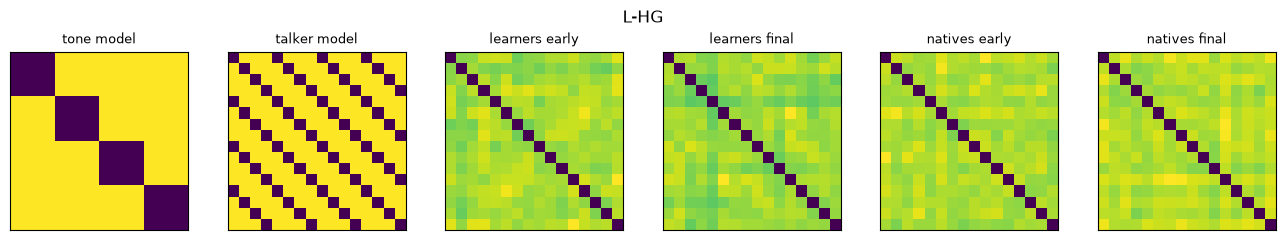

In [4]:
qc_roi = 'L-HG'
vectors, stimuli = mvd.group_mean_rdms(rdms, participants)
models = mvd.model_rdms(stimuli)
order = np.argsort(stimuli)   # tone-major

def square(vector):
    n = len(stimuli)
    m = np.zeros((n, n))
    m[np.triu_indices(n, 1)] = vector
    m = m + m.T
    return m[np.ix_(order, order)]

panels = [(f'{f} model', models[f].get_vectors()[0]) for f in models]
panels += [(f'{labels[g]} {stage}', np.mean(list(vectors[(g, stage, qc_roi)].values()), axis=0))
           for g in gs.GROUPS for stage in ('early', 'final') if (g, stage, qc_roi) in vectors]
fig, axes = plt.subplots(1, len(panels), figsize=(2.2 * len(panels), 2.4))
for ax, (title, vector) in zip(axes, panels):
    ax.imshow(square(vector), cmap='viridis')
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(qc_roi)
fig.tight_layout()

### Noise ceiling

Per group × stage × ROI: lower and upper bounds on the fit any model could reach given between-subject reliability. A low ceiling means that ROI's RDMs are too noisy to interpret a null fit.

In [5]:
ceiling = mvd.noise_ceiling(rdms, participants, method=compare_method)
ceiling.to_csv(os.path.join(out_dir, 'noise_ceiling.tsv'), sep='\t', index=False)
ceiling.pivot_table(index='region_hemi', columns=['participant_group', 'learning_stage'], values='lower').round(3)

participant_group Mandarin               non-Mandarin              
learning_stage       early  final middle        early  final middle
region_hemi                                                        
L-Caud              -0.014  0.029  0.021       -0.064  0.040  0.011
L-HG                -0.064 -0.053 -0.050        0.019  0.036 -0.021
L-IC                 0.000 -0.007 -0.020       -0.030  0.024  0.002
L-MGN               -0.023 -0.002  0.021       -0.007 -0.017  0.006
L-PP                -0.030  0.053 -0.043       -0.001 -0.009 -0.020
L-PT                -0.025  0.066 -0.021        0.017 -0.055 -0.010
L-ParsOp            -0.019  0.051  0.003        0.019  0.042  0.063
L-ParsTri           -0.025  0.055 -0.026        0.010  0.007  0.071
L-Put               -0.038 -0.004 -0.012       -0.005 -0.030 -0.026
L-STGa              -0.035  0.019 -0.003       -0.070  0.024  0.004
L-STGp              -0.002  0.070  0.011        0.038 -0.020  0.060
NAc-core-lh          0.044  0.080 -0.016       -0.034  0.017 -0.007
NAc-core-rh          0.077  0.035  0.040       -0.088 -0.001  0.073
NAc-shell-lh        -0.042 -0.003 -0.008       -0.047 -0.019  0.019
NAc-shell-rh        -0.030 -0.016  0.007       -0.003  0.036 -0.001
R-Caud              -0.012  0.070  0.078       -0.018 -0.026 -0.040
R-HG                 0.007 -0.005  0.003        0.026 -0.023 -0.033
R-IC                 0.019  0.022 -0.007       -0.029  0.042  0.025
R-MGN               -0.036  0.006  0.005        0.030 -0.060  0.003
R-PP                -0.121  0.061 -0.018       -0.011 -0.009 -0.060
R-PT                 0.009  0.026 -0.005       -0.019  0.016  0.019
R-ParsOp            -0.014  0.048  0.006       -0.035 -0.037 -0.013
R-ParsTri            0.068  0.017  0.003       -0.051 -0.054 -0.002
R-Put               -0.016  0.031  0.056       -0.029  0.017 -0.048
R-STGa              -0.029  0.096  0.034        0.020 -0.033  0.018
R-STGp               0.018  0.043  0.013       -0.009  0.003  0.060
aCAU-lh              0.031  0.053 -0.002       -0.012  0.075  0.030
aCAU-rh             -0.040  0.080  0.119        0.006  0.011 -0.039
aPUT-lh             -0.058  0.009 -0.018       -0.004  0.018 -0.015
aPUT-rh              0.035  0.033  0.086        0.000  0.056 -0.036
pCAU-lh             -0.069 -0.011  0.032       -0.018  0.074  0.007
pCAU-rh              0.004  0.069  0.012        0.025 -0.020 -0.056
pPUT-lh              0.018  0.006  0.008       -0.043 -0.048  0.019
pPUT-rh             -0.032  0.041  0.039       -0.051  0.007  0.044

## 2. Model fits by stage and group

Hemispheres averaged per participant; mean ± SEM.

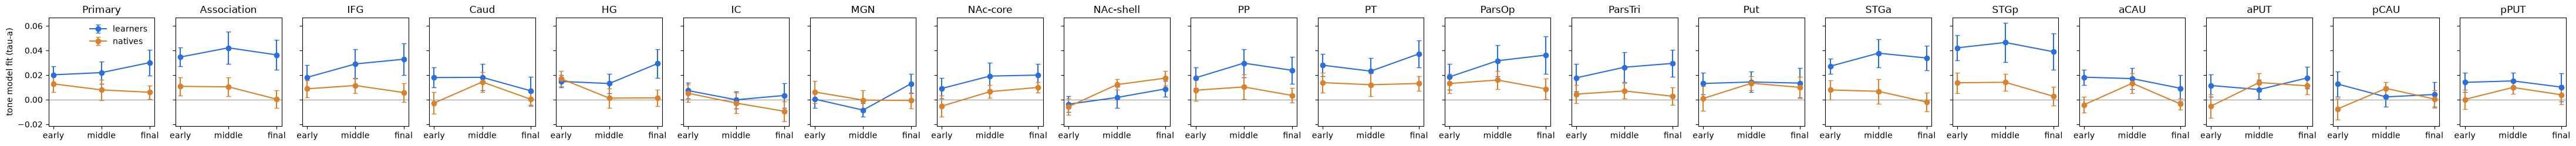

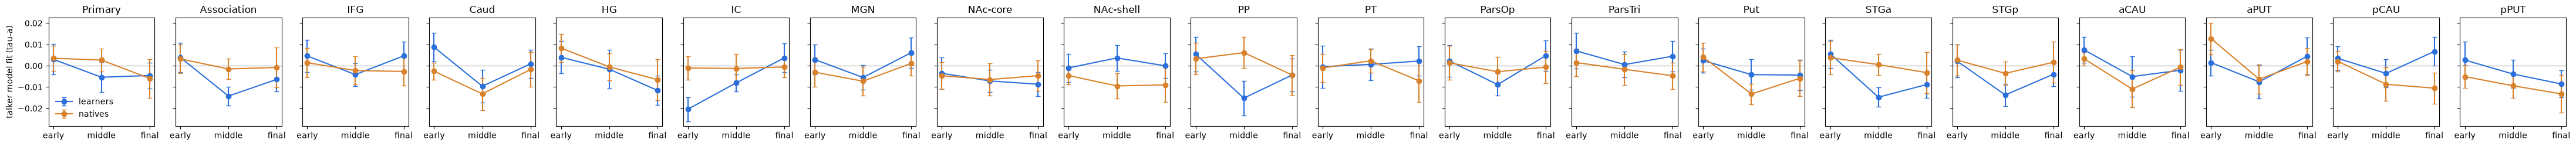

In [6]:
bilat = gs.bilateral_mean(fits)
regions = list(mvd.COMPOSITES) + sorted(r for r in bilat.region.unique() if r not in mvd.COMPOSITES)
for factor in mvd.STIMULUS_FACTORS:
    sub = bilat[bilat.contrast == f'{factor}_fit']
    fig, axes = plt.subplots(1, len(regions), figsize=(2.2 * len(regions), 2.6), sharey=True)
    for ax, region in zip(np.atleast_1d(axes), regions):
        for group in gs.GROUPS:
            g = sub[(sub.region == region) & (sub.participant_group == group)].groupby('learning_stage').beta
            ax.errorbar(range(3), g.mean().reindex(gs.STAGE_ORDER), yerr=g.sem().reindex(gs.STAGE_ORDER),
                        marker='o', capsize=3, color=colors[group], label=labels[group])
        ax.axhline(0, color='0.6', lw=0.8)
        ax.set_xticks(range(3), gs.STAGE_ORDER)
        ax.set_title(region)
    np.atleast_1d(axes)[0].set_ylabel(f'{factor} model fit (tau-a)')
    np.atleast_1d(axes)[0].legend(frameon=False)
    fig.tight_layout()

## 3. Is there category structure? Fit vs. 0 within each group

Per stage and stages averaged; FDR across regions within group × model × network (× stage).

In [7]:
baseline = gs.baseline_tests(fits)
baseline_by_stage = gs.baseline_tests(fits, by_stage=True)
baseline.to_csv(os.path.join(out_dir, 'fit_vs_0.tsv'), sep='\t', index=False)
baseline_by_stage.to_csv(os.path.join(out_dir, 'fit_vs_0_by-stage.tsv'), sep='\t', index=False)
baseline_by_stage[baseline_by_stage.contrast == 'tone_fit'].pivot_table(
    index=['network', 'region'], columns=['participant_group', 'learning_stage'], values='t').round(2)

participant_group              Mandarin              non-Mandarin             
learning_stage                    early final middle        early final middle
network            region                                                     
auditory           HG              2.78  0.21   0.16         2.94  2.55   1.69
                   PP              0.89  0.57   1.02         2.15  2.21   2.60
                   PT              1.69  2.21   1.31         3.04  3.38   2.19
                   ParsOp          1.67  1.06   2.12         1.75  2.36   2.51
                   ParsTri         0.59  0.39   1.15         1.59  2.69   2.15
                   STGa            0.99 -0.27   0.67         4.31  3.38   3.29
                   STGp            1.64  0.36   2.06         4.12  2.62   2.89
auditory-composite Association     1.48  0.05   1.36         4.51  3.00   3.17
                   IFG             1.25  0.77   1.86         1.77  2.56   2.41
                   Primary         1.98  1.07   0.93         2.94  2.84   2.41
striatum-whole     Caud           -0.31  0.06   1.79         2.21  0.64   1.68
                   Put             0.10  1.20   2.31         1.50  1.12   1.72
subcort-aud        IC              0.72 -1.18  -0.34         1.16  0.34  -0.02
                   MGN             0.68 -0.10  -0.05         0.06  1.70  -1.55
tian-S2            NAc-core       -0.60  2.23   1.24         1.09  2.22   1.75
                   NAc-shell      -0.86  2.91   2.79        -0.57  1.37   0.20
                   aCAU           -0.65 -0.79   1.66         2.92  0.85   1.98
                   aPUT           -0.55  1.66   1.88         1.24  2.01   1.06
                   pCAU           -0.87  0.07   1.73         1.21  0.42   0.28
                   pPUT            0.02  0.51   1.85         1.77  0.89   2.32

## 4. Does tone structure emerge with learning? Trend, learners vs. natives

Per-participant `[-1, 0, 1]` trend (final − early) in tone fit, compared between groups. The full battery (sign-flip, LOSO, bootstrap, group-label permutation) runs on the composites and the two striatal regions of the univariate headline (aCAU, aPUT); every region gets the Welch/permutation test with FDR. Talker fit alongside as the control -- but the fits aren't independent: tau-a is rank-based, so as tone structure grows, the same RDM ranks talker pairs lower and talker fit falls even if talker information is unchanged (seen in synthetic data). Read a talker-fit decline next to a tone-fit rise as a shift in relative structure, not lost talker information; a model fitting both at once (e.g. rsatoolbox `ModelWeighted` with tone and talker components) would separate them. Exploratory: no RSA test was pre-specified.

In [8]:
trends = gs.subject_trends(fits)
focus = [r for r in list(mvd.COMPOSITES) + ['aCAU', 'aPUT'] if r in set(trends.region)]
battery = pd.concat([gs.trend_group_difference(trends, f'{factor}_fit', region,
                                               n_perms=n_perms, n_boot=n_boot, seed=seed)
                     for factor in mvd.STIMULUS_FACTORS for region in focus], ignore_index=True)
battery.to_csv(os.path.join(out_dir, 'fit_trend_focus-regions.tsv'), sep='\t', index=False)
battery.round(3)

,test,n,estimate,t,p,permutation_p,loso_preserved,ci_lower,ci_upper,contrast,region
0,non-Mandarin trend vs 0,12,0.010,0.906,0.384,0.391,0/12,-0.009,0.032,tone_fit,Primary
1,Mandarin trend vs 0,13,-0.007,-0.817,0.430,0.430,0/13,-0.022,0.009,tone_fit,Primary
2,non-Mandarin - Mandarin (Welch),25,0.017,1.216,0.238,0.235,0/25,-0.009,0.043,tone_fit,Primary
3,non-Mandarin trend vs 0,12,0.002,0.119,0.907,0.905,0/12,-0.026,0.030,tone_fit,Association
4,Mandarin trend vs 0,13,-0.010,-1.007,0.334,0.347,1/13,-0.028,0.011,tone_fit,Association
5,non-Mandarin - Mandarin (Welch),25,0.012,0.675,0.507,0.506,0/25,-0.023,0.046,tone_fit,Association
6,non-Mandarin trend vs 0,12,0.015,1.034,0.324,0.328,0/12,-0.011,0.042,tone_fit,IFG
7,Mandarin trend vs 0,13,-0.003,-0.286,0.780,0.784,0/13,-0.022,0.017,tone_fit,IFG
8,non-Mandarin - Mandarin (Welch),25,0.018,0.999,0.329,0.323,0/25,-0.016,0.051,tone_fit,IFG
9,non-Mandarin trend vs 0,12,-0.009,-0.777,0.453,0.444,0/12,-0.030,0.014,tone_fit,aCAU


In [9]:
per_region = fits[~fits.region.isin(mvd.COMPOSITES)]
trend_diff = gs.trend_difference_tests(gs.subject_trends(per_region),
                                       contrasts=[f'{f}_fit' for f in mvd.STIMULUS_FACTORS],
                                       n_perms=n_perms, seed=seed)
trend_diff.to_csv(os.path.join(out_dir, 'fit_trend_group-difference.tsv'), sep='\t', index=False)
trend_diff.round(3)

,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory,talker_fit,HG,12,13,-0.016,-0.015,-0.001,-0.042,0.967,-0.017,-0.801,0.768,0.969,0.967
1,auditory,talker_fit,PP,12,13,-0.010,-0.008,-0.002,-0.140,0.890,-0.056,-0.841,0.729,0.888,0.967
2,auditory,talker_fit,PT,12,13,0.003,-0.006,0.009,0.575,0.571,0.233,-0.555,1.020,0.560,0.967
3,auditory,talker_fit,ParsOp,12,13,0.003,-0.002,0.005,0.322,0.750,0.128,-0.657,0.913,0.755,0.967
4,auditory,talker_fit,ParsTri,12,13,-0.002,-0.006,0.004,0.257,0.800,0.102,-0.683,0.888,0.798,0.967
5,auditory,talker_fit,STGa,12,13,-0.014,-0.007,-0.007,-0.570,0.574,-0.227,-1.014,0.560,0.586,0.967
6,auditory,talker_fit,STGp,12,13,-0.006,-0.001,-0.005,-0.303,0.765,-0.120,-0.905,0.666,0.771,0.967
7,auditory,tone_fit,HG,12,13,0.014,-0.016,0.030,2.105,0.047,0.845,0.027,1.664,0.049,0.327
8,auditory,tone_fit,PP,12,13,0.006,-0.004,0.010,0.636,0.531,0.255,-0.532,1.043,0.525,0.620
9,auditory,tone_fit,PT,12,13,0.009,-0.001,0.010,0.644,0.527,0.262,-0.526,1.050,0.523,0.620


## 5. Do natives start ahead and learners catch up? Group difference per stage

Learners − natives per stage (negative = natives higher). The category-knowledge prediction is a negative difference early that shrinks by the final stage. FDR across regions within model × network × stage.

In [10]:
stage_diff = gs.group_difference_tests(per_region, contrasts=[f'{f}_fit' for f in mvd.STIMULUS_FACTORS],
                                       by_stage=True, n_perms=n_perms, seed=seed)
stage_diff.to_csv(os.path.join(out_dir, 'fit_group-difference_by-stage.tsv'), sep='\t', index=False)
stage_diff[stage_diff.contrast == 'tone_fit'].pivot_table(
    index=['network', 'region'], columns='learning_stage', values='d')[list(gs.STAGE_ORDER)].round(2)

learning_stage            early  middle  final
network        region                         
auditory       HG         -0.11    0.43   0.85
               PP          0.34    0.51   0.68
               PT          0.46    0.32   0.79
               ParsOp      0.16    0.44   0.65
               ParsTri     0.40    0.58   0.83
               STGa        0.75    0.82   1.16
               STGp        0.87    0.76   0.89
striatum-whole Caud        0.69    0.11   0.22
               Put         0.36    0.04   0.10
subcort-aud    IC          0.09    0.10   0.40
               MGN        -0.20   -0.33   0.55
tian-S2        NAc-core    0.47    0.43   0.41
               NAc-shell   0.09   -0.45  -0.40
               aCAU        1.00    0.13   0.45
               aPUT        0.50   -0.21   0.23
               pCAU        0.60   -0.29   0.12
               pPUT        0.49    0.25   0.18

In [11]:
anova = gs.group_by_stage_anova(per_region)
anova.to_csv(os.path.join(out_dir, 'fit_group-by-stage-anova.tsv'), sep='\t', index=False)
anova[anova.q < .05].round(3)

,network,contrast,region,effect,F,df1,df2,p,np2,n_per_group,q
36,auditory,tone_fit,STGa,group,15.558,1,23,0.001,0.403,"{'Mandarin': 13, 'non-Mandarin': 12}",0.011
39,auditory,tone_fit,STGp,group,10.215,1,23,0.004,0.308,"{'Mandarin': 13, 'non-Mandarin': 12}",0.034


## 6. Does the representation change? Stage-to-stage RDM stability

Within each participant and ROI, the correlation between two stages' RDMs (early–middle, middle–final, early–final). This tests whether the geometry changes, not just how strongly tone is represented. Prediction: natives are stable throughout. Learners change, so early–final < middle–final as their representation settles. Learners − natives per stage pair (FDR across regions within network × pair), plus learners' within-group comparison of the early–final and middle–final pairs.

**Check:** a noisier RDM correlates less with anything, so low early stability could mean a noisy early RDM rather than change. The mean cross-validated distance per stage is tested the same way. A stability difference matched by a distance difference in the same direction isn't evidence of change.

In [12]:
stability = mvd.add_composites(mvd.stage_stability(rdms, participants))
distance = mvd.add_composites(mvd.mean_distance(rdms, participants))

stability_diff = gs.group_difference_tests(stability[~stability.region.isin(mvd.COMPOSITES)],
                                           contrasts=('stage_stability',), by_stage=True, n_perms=n_perms, seed=seed)
stability_diff.to_csv(os.path.join(out_dir, 'stage-stability_group-difference.tsv'), sep='\t', index=False)

# learners: does stability rise as the representation settles? (paired, per region, composites included)
bilat_stab = gs.bilateral_mean(stability)
learners_stab = bilat_stab[bilat_stab.participant_group == 'non-Mandarin'].pivot_table(
    index=['region', 'participant_id'], columns='learning_stage', values='beta')
settling = (learners_stab['middle-final'] - learners_stab['early-final']).groupby('region').agg(
    ['mean', 'count', lambda x: stats.ttest_1samp(x, 0).pvalue]).set_axis(['mean', 'n', 'p'], axis=1)
print('learners, middle-final minus early-final stability:')
print(settling.round(3))
stability_diff.pivot_table(index=['network', 'region'], columns='learning_stage', values='d').round(2)

learners, middle-final minus early-final stability:
              mean   n      p
region                       
Association  0.076  12  0.146
Caud         0.019  12  0.704
HG           0.043  12  0.253
IC          -0.023  12  0.538
IFG          0.046  12  0.475
MGN         -0.024  12  0.690
NAc-core     0.075  12  0.166
NAc-shell    0.051  12  0.369
PP           0.007  12  0.864
PT           0.079  12  0.075
ParsOp       0.023  12  0.731
ParsTri      0.070  12  0.336
Primary      0.043  12  0.170
Put          0.066  12  0.186
STGa         0.066  12  0.315
STGp         0.087  12  0.057
aCAU         0.034  12  0.363
aPUT         0.038  12  0.242
pCAU        -0.001  12  0.987
pPUT         0.062  12  0.282


learning_stage            early-final  early-middle  middle-final
network        region                                            
auditory       HG               -0.42         -0.10          0.65
               PP               -0.81          0.35          0.12
               PT               -0.42          0.41          0.46
               ParsOp           -0.00          0.60          0.51
               ParsTri          -0.59          0.11          0.37
               STGa             -0.64          0.40         -0.03
               STGp             -0.40          0.69          0.44
striatum-whole Caud             -0.43          0.65          0.07
               Put              -0.39          0.23          0.26
subcort-aud    IC                0.10         -0.53         -0.51
               MGN              -0.23         -0.21         -0.33
tian-S2        NAc-core         -0.54          0.21         -0.00
               NAc-shell        -0.29          0.40          0.82
               aCAU             -0.30          0.40          0.19
               aPUT             -0.79          1.15         -0.30
               pCAU              0.15         -0.13          0.13
               pPUT             -0.20         -0.35          0.21

In [13]:
# signal-strength check: mean cross-validated distance, learners - natives per stage
distance_diff = gs.group_difference_tests(distance[~distance.region.isin(mvd.COMPOSITES)],
                                          contrasts=('mean_distance',), by_stage=True, n_perms=n_perms, seed=seed)
distance_diff.to_csv(os.path.join(out_dir, 'mean-distance_group-difference_by-stage.tsv'), sep='\t', index=False)
distance_diff.pivot_table(index=['network', 'region'], columns='learning_stage', values='d')[list(gs.STAGE_ORDER)].round(2)

learning_stage            early  middle  final
network        region                         
auditory       HG         -0.15   -0.25  -0.36
               PP          0.10    0.08  -0.11
               PT         -0.20    0.16   0.01
               ParsOp      0.41    0.77   0.66
               ParsTri     0.35    0.83   0.64
               STGa        0.37    0.33   0.02
               STGp        0.36    0.60   0.28
striatum-whole Caud        1.03    0.54   0.38
               Put         0.10    0.20  -0.04
subcort-aud    IC          0.05    0.20  -0.29
               MGN         0.80    0.09  -0.33
tian-S2        NAc-core    0.62    0.69   0.72
               NAc-shell   0.50    0.34   0.33
               aCAU        0.61    0.57   0.68
               aPUT        0.23    0.29   0.10
               pCAU        1.01    0.48   0.51
               pPUT       -0.02    0.17  -0.08

## 7. Do learners become native-like? Similarity to the natives' RDM

Each participant's RDM per stage, correlated with the natives' template: their mean RDM over all stages, each native left out of their own template. Prediction: learners' native-likeness rises across stages (positive trend); natives' (their leave-one-out values, effectively a noise ceiling) stays flat.

**Control, peer-likeness:** correlation with the mean of the participant's own group at the same stage. Cleaner RDMs correlate more with everything, so learners' native-likeness should rise *more* than their peer-likeness for convergence on the native geometry. Tested per participant as the trend in native- minus peer-likeness.

In [14]:
likeness = mvd.add_composites(mvd.native_likeness(rdms, participants))
likeness_trends = gs.subject_trends(likeness)
focus = [r for r in list(mvd.COMPOSITES) + ['aCAU', 'aPUT'] if r in set(likeness_trends.region)]
native_battery = pd.concat([gs.trend_group_difference(likeness_trends, 'native_likeness', region,
                                                      n_perms=n_perms, n_boot=n_boot, seed=seed)
                            for region in focus], ignore_index=True)

# convergence beyond reliability: trend in native- minus peer-likeness
wide = likeness_trends.pivot_table(index=['network', 'participant_id', 'participant_group', 'region'],
                                   columns='contrast', values='trend').dropna()
beyond = (wide['native_likeness'] - wide['peer_likeness']).rename('trend').reset_index().assign(
    contrast='native_minus_peer')
beyond_battery = pd.concat([gs.trend_group_difference(beyond, 'native_minus_peer', region,
                                                      n_perms=n_perms, n_boot=n_boot, seed=seed)
                            for region in focus], ignore_index=True)
pd.concat([native_battery, beyond_battery]).to_csv(os.path.join(out_dir, 'native-likeness_trend.tsv'),
                                                   sep='\t', index=False)
pd.concat([native_battery, beyond_battery]).round(3)

,test,n,estimate,t,p,permutation_p,loso_preserved,ci_lower,ci_upper,contrast,region
0,non-Mandarin trend vs 0,12,0.081,2.221,0.048,0.056,4/12,0.016,0.150,native_likeness,Primary
1,Mandarin trend vs 0,13,0.061,1.954,0.074,0.069,1/13,0.006,0.122,native_likeness,Primary
2,non-Mandarin - Mandarin (Welch),25,0.019,0.404,0.690,0.691,0/25,-0.072,0.109,native_likeness,Primary
3,non-Mandarin trend vs 0,12,0.028,0.523,0.611,0.621,0/12,-0.070,0.135,native_likeness,Association
4,Mandarin trend vs 0,13,0.063,1.662,0.122,0.120,0/13,-0.007,0.137,native_likeness,Association
5,non-Mandarin - Mandarin (Welch),25,-0.035,-0.526,0.605,0.595,0/25,-0.160,0.092,native_likeness,Association
6,non-Mandarin trend vs 0,12,0.062,1.040,0.321,0.375,0/12,-0.035,0.187,native_likeness,IFG
7,Mandarin trend vs 0,13,0.072,1.413,0.183,0.183,0/13,-0.024,0.167,native_likeness,IFG
8,non-Mandarin - Mandarin (Welch),25,-0.009,-0.121,0.905,0.903,0/25,-0.151,0.147,native_likeness,IFG
9,non-Mandarin trend vs 0,12,0.033,0.630,0.542,0.543,0/12,-0.070,0.129,native_likeness,aCAU


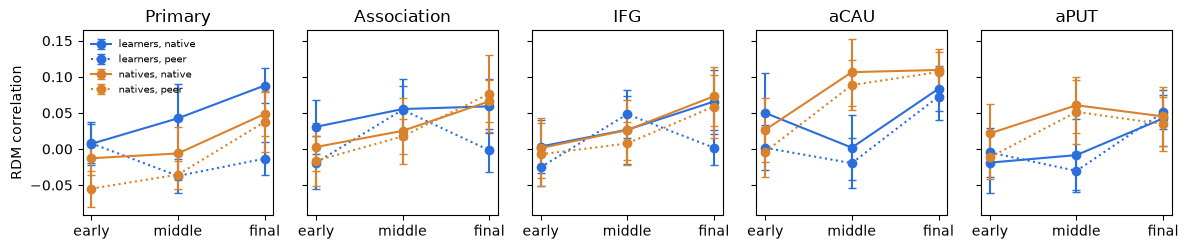

In [15]:
bilat_like = gs.bilateral_mean(likeness)
fig, axes = plt.subplots(1, len(focus), figsize=(2.4 * len(focus), 2.6), sharey=True)
for ax, region in zip(np.atleast_1d(axes), focus):
    for group in gs.GROUPS:
        for contrast, ls in [('native_likeness', '-'), ('peer_likeness', ':')]:
            g = bilat_like[(bilat_like.region == region) & (bilat_like.participant_group == group)
                           & (bilat_like.contrast == contrast)].groupby('learning_stage').beta
            ax.errorbar(range(3), g.mean().reindex(gs.STAGE_ORDER), yerr=g.sem().reindex(gs.STAGE_ORDER),
                        marker='o', ls=ls, capsize=3, color=colors[group],
                        label=f"{labels[group]}, {contrast.split('_')[0]}")
    ax.set_xticks(range(3), gs.STAGE_ORDER)
    ax.set_title(region)
np.atleast_1d(axes)[0].set_ylabel('RDM correlation')
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=7)
fig.tight_layout()

## 8. Is learners' shared aCAU geometry behavioral? Accuracy and confusion model RDMs

Section 7 found learners' aCAU RDMs converging on each other (not on the natives') by the final stage, with no tone structure. Hypothesis: the geometry reflects how often each stimulus is answered correctly -- each stimulus's mean pattern mixes correct- and wrong-feedback trials, and if the same stimuli are hard for every learner, that structure is shared. The univariate feedback contrast declines in the same region (learners' aCAU fbcorrectvswrong trend).

Per learner × stage, from the events files (the stage's ~6 trials per stimulus):
- **accuracy** model: `|acc_s − acc_t|` (feedback history)
- **confusion** model: distance between the stimuli's response-proportion vectors (how the learner categorizes them; equals the tone model when they're perfect)
- each from the learner's **own** behavior and from the **group** (other learners' mean that stage = shared stimulus difficulty)

Learners only: natives near ceiling give accuracy models with little or no variance (left out when constant). Missed responses are dropped (`noresp='drop'`).

Predictions: accuracy (or confusion) fit > 0 in learners' aCAU at the final stage, beyond tone (regression), rising across stages with peer-likeness; auditory cortex tone/confusion more than accuracy.

In [16]:
sys.path.insert(0, '..')
import resampling_stats as rs

trials = mvd.load_behavior(bidsroot, participants)
print('trials per group x stage:')
print(trials.groupby(['participant_group', 'learning_stage']).size().unstack()[list(gs.STAGE_ORDER)])

# checks: key mapping (correct key's tone = stimulus tone), feedback agrees with the response,
# and the stimulus-to-feedback delay (for feedback to show up in a trial's beta it has to fall
# within the HRF of the sound regressor)
answered = trials.dropna(subset=['correct_tone'])
print(f"\ncorrect key's tone == stimulus tone: {(answered.correct_tone == answered.tone).mean():.3f}")
scored = trials.dropna(subset=['correct', 'response_tone'])
print(f"fb_correct == (response tone == stimulus tone): {((scored.response_tone == scored.tone) == (scored.correct == 1)).mean():.3f}")
print('missed responses:', (trials.feedback == 'fb_noresp').mean().round(3))
print('\nsound -> feedback onset (s):')
print(trials.fb_delay.describe().round(2))

trials per group x stage:
learning_stage     early  middle  final
participant_group                      
Mandarin            1248    1248   1248
non-Mandarin        1152    1152   1152

correct key's tone == stimulus tone: 1.000
fb_correct == (response tone == stimulus tone): 1.000
missed responses: 0.028

sound -> feedback onset (s):
count    7200.00
mean        3.48
std         0.58
min         2.45
25%         2.96
50%         3.48
75%         3.98
max         4.50
Name: fb_delay, dtype: float64


learners: r(own per-stimulus accuracy, other learners' mean)
                 mean  count      p
learning_stage                     
early           0.339     12  0.012
middle          0.437     12  0.001
final           0.315     12  0.004


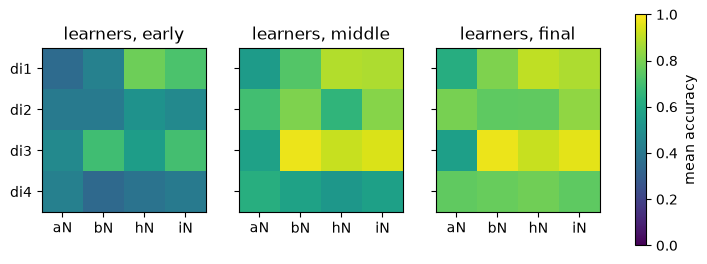

In [17]:
# per-stimulus accuracy: is difficulty shared across learners? (each learner's per-stimulus
# accuracy correlated with the other learners' mean, per stage)
stim_beh = mvd.stimulus_behavior(trials)
learner_beh = stim_beh[stim_beh.participant_group == 'non-Mandarin']
shared = []
for (p, stage), sub in learner_beh.groupby(['participant_id', 'learning_stage']):
    others = learner_beh[(learner_beh.participant_id != p) & (learner_beh.learning_stage == stage)]
    others = others.groupby('stimulus').accuracy.mean().reindex(sub.stimulus)
    shared.append({'participant_id': p, 'learning_stage': stage,
                   'r': np.corrcoef(sub.accuracy, others)[0, 1] if sub.accuracy.std() > 0 else np.nan})
shared = pd.DataFrame(shared)
print('learners: r(own per-stimulus accuracy, other learners\' mean)')
print(shared.groupby('learning_stage').r.agg(['mean', 'count'])
      .reindex(list(gs.STAGE_ORDER)).assign(p=[stats.ttest_1samp(shared[shared.learning_stage == s].r.dropna(), 0).pvalue
                                               for s in gs.STAGE_ORDER]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(9, 3), sharey=True)
for ax, stage in zip(axes, gs.STAGE_ORDER):
    grid = learner_beh[learner_beh.learning_stage == stage].groupby('stimulus').accuracy.mean()
    grid = grid.rename(lambda s: s).to_frame().assign(tone=lambda d: d.index.str.split('_').str[0],
                                                        talker=lambda d: d.index.str.split('_').str[1])
    im = ax.imshow(grid.pivot(index='tone', columns='talker', values='accuracy'), vmin=0, vmax=1, cmap='viridis')
    ax.set_title(f'learners, {stage}')
    ax.set_xticks(range(4), sorted(grid.talker.unique()))
    ax.set_yticks(range(4), sorted(grid.tone.unique()))
fig.colorbar(im, ax=axes, label='mean accuracy')
plt.show()

In [18]:
vectors_stimuli = list(next(iter(rdms.values())).pattern_descriptors['stimulus'])
behav_models = mvd.behavior_models(stim_beh, vectors_stimuli)
tone_vector = mvd.model_rdms(vectors_stimuli)['tone'].get_vectors()[0]

# how much the behavioral models overlap with the tone model (Spearman), by stage
overlap = pd.DataFrame([{'participant_id': p, 'learning_stage': stage, 'model': name,
                         'r_with_tone': stats.spearmanr(m, tone_vector)[0]}
                        for (p, stage), ms in behav_models.items() for name, m in ms.items()])
print('learners with each model, by stage:')
print(overlap.groupby(['model', 'learning_stage']).participant_id.count().unstack()[list(gs.STAGE_ORDER)])
print('\nmean Spearman r with the tone model:')
print(overlap.groupby(['model', 'learning_stage']).r_with_tone.mean().unstack()[list(gs.STAGE_ORDER)].round(2))

learners with each model, by stage:
learning_stage   early  middle  final
model                                
accuracy_group      12      12     12
accuracy_own        12      12     12
confusion_group     12      12     12
confusion_own       12      12     12

mean Spearman r with the tone model:
learning_stage   early  middle  final
model                                
accuracy_group    0.13    0.20   0.18
accuracy_own      0.10    0.09   0.04
confusion_group   0.58    0.69   0.69
confusion_own     0.32    0.52   0.59


In [19]:
behav_fits = mvd.add_composites(mvd.behavior_model_fits(rdms, participants, behav_models, method=compare_method))
behav_reg = mvd.add_composites(mvd.behavior_model_regression(rdms, participants, behav_models,
                                                            behavioral=('accuracy_own',)))

def learner_battery(df, contrast, regions):
    ''' per region: learners' values vs 0 per stage, and their [-1, 0, 1] trend vs 0
    (t, exact sign-flip, LOSO, bootstrap CI) '''
    sub = df[(df.contrast == contrast) & (df.participant_group == 'non-Mandarin')]
    bilat_sub = gs.bilateral_mean(sub)
    trend = gs.subject_trends(sub)
    rows = []
    for region in regions:
        per_stage = {s: bilat_sub[(bilat_sub.region == region) & (bilat_sub.learning_stage == s)].beta.values
                     for s in gs.STAGE_ORDER}
        t_vals = trend[trend.region == region].trend.values
        loso, exact = rs.leave_one_out_stability(t_vals), rs.exact_sign_flip_permutation_test(t_vals)
        boot = rs.bootstrap_ci(t_vals, n_boot=n_boot, rng=np.random.default_rng(seed))
        rows.append({'contrast': contrast, 'region': region,
                     **{f'{s} mean': v.mean() for s, v in per_stage.items()},
                     **{f'{s} p': stats.ttest_1samp(v, 0).pvalue for s, v in per_stage.items()},
                     'trend': boot['mean'], 'trend n': len(t_vals), 'trend p': loso['original_p'],
                     'trend perm p': exact['p_value'], 'loso': f"{loso['n_preserved']}/{loso['n_folds']}",
                     'ci': f"[{boot['ci_lower']:.3f}, {boot['ci_upper']:.3f}]"})
    return pd.DataFrame(rows)

focus = [r for r in list(mvd.COMPOSITES) + ['aCAU', 'aPUT'] if r in set(behav_fits.region)]
behav_battery = pd.concat([learner_battery(behav_fits, f'{m}_fit', focus)
                           for m in ['accuracy_own', 'accuracy_group', 'confusion_own', 'confusion_group']]
                          + [learner_battery(behav_reg, f'{m}_beta', focus) for m in ['accuracy_own', 'tone']],
                          ignore_index=True)
behav_battery.to_csv(os.path.join(out_dir, 'behavior-model_learners.tsv'), sep='\t', index=False)
behav_battery.round(3)

,contrast,region,early mean,middle mean,final mean,early p,middle p,final p,trend,trend n,trend p,trend perm p,loso,ci
0,accuracy_own_fit,Primary,-0.018,0.016,0.018,0.336,0.506,0.315,0.036,12,0.173,0.169,0/12,"[-0.011, 0.082]"
1,accuracy_own_fit,Association,0.004,0.019,0.010,0.828,0.364,0.532,0.006,12,0.829,0.827,0/12,"[-0.046, 0.054]"
2,accuracy_own_fit,IFG,-0.008,0.031,0.039,0.671,0.288,0.151,0.048,12,0.184,0.188,0/12,"[-0.014, 0.113]"
3,accuracy_own_fit,aCAU,0.017,0.018,0.038,0.446,0.446,0.088,0.021,12,0.534,0.525,0/12,"[-0.039, 0.079]"
4,accuracy_own_fit,aPUT,-0.000,-0.011,0.010,0.993,0.713,0.694,0.010,12,0.795,0.794,0/12,"[-0.063, 0.081]"
5,accuracy_group_fit,Primary,0.003,0.027,0.057,0.886,0.162,0.042,0.053,12,0.127,0.118,1/12,"[-0.008, 0.113]"
6,accuracy_group_fit,Association,0.024,0.050,0.064,0.309,0.024,0.037,0.040,12,0.362,0.370,0/12,"[-0.036, 0.123]"
7,accuracy_group_fit,IFG,-0.001,0.056,0.069,0.969,0.029,0.110,0.069,12,0.220,0.215,0/12,"[-0.029, 0.172]"
8,accuracy_group_fit,aCAU,-0.007,0.016,0.063,0.765,0.382,0.049,0.070,12,0.119,0.119,0/12,"[-0.004, 0.150]"
9,accuracy_group_fit,aPUT,-0.014,0.013,0.042,0.600,0.535,0.123,0.056,12,0.194,0.200,0/12,"[-0.016, 0.132]"


In [20]:
# every region, learners, by stage: fit vs 0 with FDR across regions (as in section 3)
behav_baseline = gs.baseline_tests(behav_fits[(behav_fits.participant_group == 'non-Mandarin')
                                              & ~behav_fits.region.isin(mvd.COMPOSITES)], by_stage=True)
behav_baseline.to_csv(os.path.join(out_dir, 'behavior-model_fit_vs_0_by-stage.tsv'), sep='\t', index=False)
behav_baseline.pivot_table(index=['network', 'region'], columns=['contrast', 'learning_stage'],
                           values='t')[[(f'{m}_fit', s) for m in ['accuracy_own', 'accuracy_group', 'confusion_own']
                                        for s in gs.STAGE_ORDER]].round(2)

contrast                 accuracy_own_fit              accuracy_group_fit              confusion_own_fit             
learning_stage                      early middle final              early middle final             early middle final
network        region                                                                                                
auditory       HG                   -2.26   0.65  0.99               0.33   1.44  2.83              1.08   1.11  1.36
               PP                   -0.40   0.74  1.03              -0.10   0.87  1.84              1.70   1.92  1.28
               PT                   -0.06   0.57  0.72               0.14   2.10  1.89              1.60   2.35  4.22
               ParsOp               -0.54   1.29  1.83               0.10   3.03  1.71              1.79   4.02  1.40
               ParsTri              -0.26   0.93  1.19              -0.17   2.00  1.67              1.39   2.94  1.62
               STGa                  0.74   0.65  0.06               0.92   2.44  2.38              2.58   2.48  2.91
               STGp                 -0.41   1.21  1.06               1.08   2.61  2.20              1.72   3.75  2.19
striatum-whole Caud                  0.49   0.97  1.04              -0.03   0.79  1.46              1.36   2.56 -1.21
               Put                  -0.51  -0.41  0.47              -0.48   1.08  1.30              1.89   0.99 -0.66
subcort-aud    IC                   -2.05   0.20 -1.42              -0.48   0.34  0.38              0.40  -0.51  0.91
               MGN                  -0.40   0.02 -0.32              -2.02  -0.32  0.16              0.50  -1.97  0.72
tian-S2        NAc-core              0.04   0.07  0.26               0.72   2.14  1.12              0.07   1.57  0.44
               NAc-shell             1.11  -0.69  0.21               1.07   2.79  1.26              0.79   2.30 -0.70
               aCAU                  0.79   0.79  1.87              -0.31   0.91  2.22              1.07   1.21 -1.73
               aPUT                 -0.01  -0.38  0.40              -0.54   0.64  1.67              1.04   1.33 -0.84
               pCAU                  0.44   0.46  0.92              -0.50   0.71  1.25              1.87   1.66 -1.64
               pPUT                 -0.65  -0.22  0.69               0.09   0.74  0.58              1.99   0.05 -1.17

In [21]:
# does the behavioral fit track the aCAU convergence (section 7)? Per learner, the aCAU trend in
# accuracy-model fit vs. the trend in peer-likeness
link = gs.subject_trends(behav_fits[behav_fits.participant_group == 'non-Mandarin']).pivot_table(
    index=['participant_id', 'region'], columns='contrast', values='trend').join(
    likeness_trends[likeness_trends.participant_group == 'non-Mandarin'].pivot_table(
        index=['participant_id', 'region'], columns='contrast', values='trend'))
for region in ['aCAU', 'aPUT', 'Primary']:
    sub = link.xs(region, level='region')
    for model in ['accuracy_own_fit', 'accuracy_group_fit']:
        ok = sub[[model, 'peer_likeness']].dropna()
        r, p = stats.pearsonr(ok[model], ok.peer_likeness)
        print(f'{region}: r({model} trend, peer-likeness trend) = {r:.2f}, p = {p:.3f}, n = {len(ok)}')

aCAU: r(accuracy_own_fit trend, peer-likeness trend) = -0.09, p = 0.771, n = 12
aCAU: r(accuracy_group_fit trend, peer-likeness trend) = -0.16, p = 0.630, n = 12
aPUT: r(accuracy_own_fit trend, peer-likeness trend) = -0.17, p = 0.602, n = 12
aPUT: r(accuracy_group_fit trend, peer-likeness trend) = -0.03, p = 0.922, n = 12
Primary: r(accuracy_own_fit trend, peer-likeness trend) = 0.28, p = 0.371, n = 12
Primary: r(accuracy_group_fit trend, peer-likeness trend) = -0.12, p = 0.714, n = 12


### Checks on the aCAU link

Learners whose aCAU fit to their own accuracy rose most also converged most on the other learners (previous cell). Below: whether that is RDM reliability; what the shared final-stage aCAU geometry looks like; whether the negative group-confusion trend survives with tone and talker held constant; and whether the learners who converge learn more or show the univariate feedback decline.

In [22]:
# is the aCAU accuracy-fit / peer-likeness link just RDM reliability? A cleaner RDM fits every
# real model better and correlates more with peers, so tone/talker fit and mean distance
# trends should correlate with peer-likeness too if it were
ctrl = gs.subject_trends(pd.concat([fits, distance])[lambda d: d.participant_group == 'non-Mandarin']).pivot_table(
    index=['participant_id', 'region'], columns='contrast', values='trend')
aCAU = link.xs('aCAU', level='region').join(ctrl.xs('aCAU', level='region'))
for col in ['accuracy_own_fit', 'tone_fit', 'talker_fit', 'mean_distance']:
    r, p = stats.pearsonr(aCAU[col], aCAU.peer_likeness)
    print(f'{col:18s} r = {r:.2f}, p = {p:.3f}')

# partial: accuracy-fit trend vs peer-likeness trend, controlling for mean-distance trend
import statsmodels.formula.api as smf
print(smf.ols('peer_likeness ~ accuracy_own_fit + mean_distance', aCAU).fit().summary().tables[1])

# one learner driving it? leave-one-out r
print('LOO r range:', np.round([stats.pearsonr(aCAU.drop(i).accuracy_own_fit, aCAU.drop(i).peer_likeness)[0]
                                for i in aCAU.index], 2))


accuracy_own_fit   r = -0.09, p = 0.771
tone_fit           r = 0.18, p = 0.571
talker_fit         r = -0.48, p = 0.112
mean_distance      r = -0.33, p = 0.302
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.0543      0.053      1.022      0.333      -0.066       0.174
accuracy_own_fit     0.0495      0.492      0.101      0.922      -1.063       1.161
mean_distance       -0.8890      0.895     -0.994      0.346      -2.913       1.135
LOO r range: [-0.14 -0.1  -0.3   0.05  0.   -0.22  0.18 -0.12 -0.08 -0.13 -0.1  -0.11]


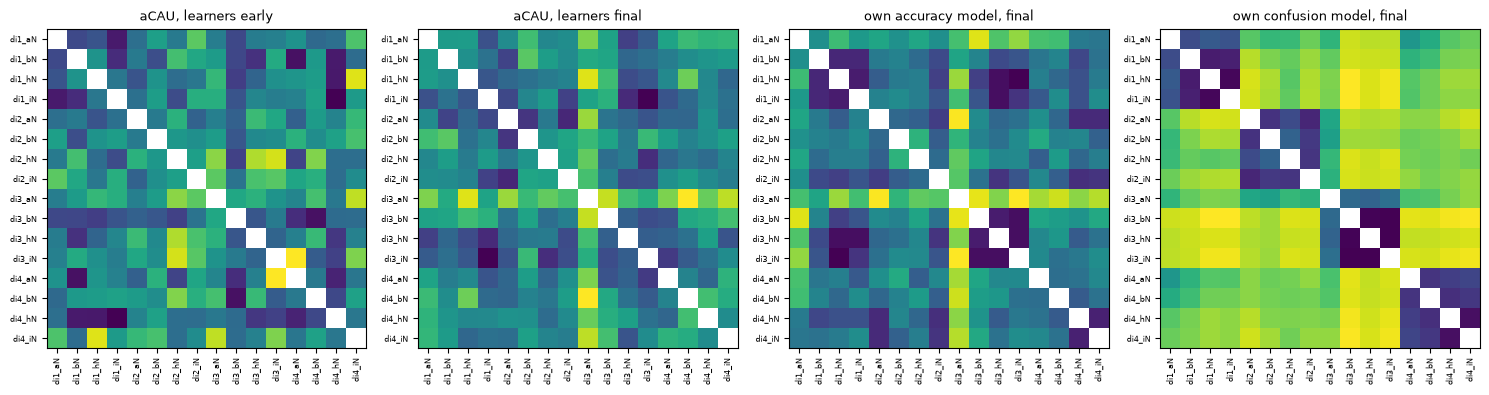

Spearman r, learners' final aCAU mean RDM with:
  own accuracy model, final: 0.47
  own confusion model, final: -0.27
  tone model: 0.01


In [23]:
# what the shared geometry looks like: learners' group-mean aCAU RDM (hemispheres averaged),
# early and final, next to the learners' mean own-accuracy and own-confusion models (final).
# Stimuli tone-major; each panel scaled on its own (diagonal blank)
group_vectors, stimuli = mvd.group_mean_rdms(rdms, participants)
order = np.argsort(stimuli)
learner_ids = participants[participants.participant_group == 'non-Mandarin'].participant_id

def square(vector):
    m = np.zeros((len(stimuli), len(stimuli)))
    m[np.triu_indices(len(stimuli), 1)] = vector
    m = m + m.T
    np.fill_diagonal(m, np.nan)
    return m[np.ix_(order, order)]

def mean_model(name, stage):
    return np.mean([behav_models[(p, stage)][name] for p in learner_ids if name in behav_models.get((p, stage), {})], axis=0)

acau = lambda stage: np.mean([np.mean(list(group_vectors[('non-Mandarin', stage, h)].values()), axis=0)
                              for h in ['aCAU-lh', 'aCAU-rh']], axis=0)
panels = [('aCAU, learners early', acau('early')), ('aCAU, learners final', acau('final')),
          ('own accuracy model, final', mean_model('accuracy_own', 'final')),
          ('own confusion model, final', mean_model('confusion_own', 'final'))]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (title, vector) in zip(axes, panels):
    ax.imshow(square(vector), cmap='viridis')
    ax.set_title(title, fontsize=9)
    ax.set_xticks(range(len(stimuli)), np.array(stimuli)[order], rotation=90, fontsize=6)
    ax.set_yticks(range(len(stimuli)), np.array(stimuli)[order], fontsize=6)
plt.tight_layout()
plt.show()
print('Spearman r, learners\' final aCAU mean RDM with:')
for title, vector in panels[2:]:
    print(f'  {title}: {stats.spearmanr(acau("final"), vector)[0]:.2f}')
print(f'  tone model: {stats.spearmanr(acau("final"), mvd.model_rdms(stimuli)["tone"].get_vectors()[0])[0]:.2f}')

In [ ]:
# the negative group-confusion trend in aCAU (learner battery above): does it survive with tone and
# talker in the model? confusion_group overlaps tone (r ~ .6-.7), so the fit alone can't tell
reg_conf = mvd.add_composites(mvd.behavior_model_regression(rdms, participants, behav_models,
                                                           behavioral=('confusion_group',)))
conf_battery = pd.concat([learner_battery(reg_conf, f'{m}_beta', focus) for m in ['confusion_group', 'tone']],
                         ignore_index=True)
conf_battery.round(3)

### Do the learners who converge learn more? Is it the univariate feedback decline?

Per learner: aCAU trends in own-accuracy fit and peer-likeness, against (a) behavioral accuracy gain (final − early) and final accuracy, and (b) the univariate aCAU `fbcorrectvswrong` trend (negative = decline; `group_level_two_group.ipynb` exports `subject_trends.tsv`). n = 12, so Spearman alongside Pearson.

In [ ]:
uni_trends_fpath = ('/ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/'
                    'group_space-T1w_fwhm-0.00/stats_two-group/subject_trends.tsv')
uni = pd.read_csv(uni_trends_fpath, sep='\t')
uni_fb = uni[(uni.contrast == 'fbcorrectvswrong') & (uni.region == 'aCAU')
             & (uni.participant_group == 'non-Mandarin')].set_index('participant_id').trend.rename('univariate_fb_trend')

acc_stage = (trials[trials.participant_group == 'non-Mandarin'].dropna(subset=['correct'])
             .groupby(['participant_id', 'learning_stage']).correct.mean().unstack())
learner_scalars = aCAU[['accuracy_own_fit', 'peer_likeness']].join(
    [(acc_stage['final'] - acc_stage['early']).rename('accuracy_gain'),
     acc_stage['final'].rename('final_accuracy'), uni_fb])

rows = []
for neural in ['accuracy_own_fit', 'peer_likeness']:
    for other in ['accuracy_gain', 'final_accuracy', 'univariate_fb_trend']:
        ok = learner_scalars[[neural, other]].dropna()
        r, p = stats.pearsonr(ok[neural], ok[other])
        rho, p_rho = stats.spearmanr(ok[neural], ok[other])
        rows.append({'aCAU trend': neural, 'vs': other, 'n': len(ok), 'r': r, 'p': p, 'rho': rho, 'p_rho': p_rho})
learner_links = pd.DataFrame(rows)
learner_links.to_csv(os.path.join(out_dir, 'aCAU_learner-links.tsv'), sep='\t', index=False)
learner_links.round(3)

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
for row, neural in zip(axes, ['accuracy_own_fit', 'peer_likeness']):
    for ax, other in zip(row, ['accuracy_gain', 'final_accuracy', 'univariate_fb_trend']):
        ok = learner_scalars[[neural, other]].dropna()
        ax.scatter(ok[other], ok[neural], color=colors['non-Mandarin'])
        ax.set_xlabel(other.replace('_', ' '))
        ax.set_ylabel(f'aCAU {neural.replace("_", " ")} trend')
        ax.set_title(f'r = {stats.pearsonr(ok[other], ok[neural])[0]:.2f}', fontsize=9)
plt.tight_layout()
plt.show()

### Is the aCAU convergence one stimulus?

In the group-mean RDM image, learners' final aCAU geometry looks dominated by di3_aN (the stimulus they still miss most), and peer-likeness is a Pearson correlation, which one stimulus far from all the others can drive. Three checks: (1) per stimulus, distinctiveness in aCAU (mean distance to the other 15) and error rate, both groups; (2) within each learner, does distinctiveness track their own per-stimulus error rate (a per-stimulus version of the accuracy model that no single stimulus drives)?; (3) peer-likeness recomputed without the most distinctive stimulus, and with rank-transformed RDMs.

In [ ]:
# (1) per stimulus x group x stage: aCAU distinctiveness (each RDM's row means, z-scored within the
# RDM so participants are comparable; hemispheres averaged) and error rate (missed responses dropped)
rdm_vecs = mvd.rdm_vectors(rdms)
n_stim = len(stimuli)
upper = np.triu_indices(n_stim, 1)

def distinctiveness(vector):
    m = np.zeros((n_stim, n_stim))
    m[upper] = vector
    m = m + m.T
    d = m.sum(axis=1) / (n_stim - 1)
    return (d - d.mean()) / d.std()

def hemis(region):
    return sorted({k[2] for k in rdm_vecs if mvd.split_region_hemi(k[2])[0] == region})

rows = []
for region in ['aCAU', 'aPUT', 'pCAU', 'HG', 'STGp']:
    for p, group in participants[['participant_id', 'participant_group']].itertuples(index=False):
        for stage in gs.STAGE_ORDER:
            vs = [rdm_vecs[(p, stage, h)] for h in hemis(region) if (p, stage, h) in rdm_vecs]
            if not vs:
                continue
            for stim, d in zip(stimuli, distinctiveness(np.mean(vs, axis=0))):
                rows.append({'region': region, 'participant_id': p, 'participant_group': group,
                             'learning_stage': stage, 'stimulus': stim, 'distinctiveness': d})
distinct = pd.DataFrame(rows).merge(
    stim_beh.assign(error=1 - stim_beh.accuracy)[['participant_id', 'learning_stage', 'stimulus', 'error']],
    on=['participant_id', 'learning_stage', 'stimulus'], how='left')

per_stim = (distinct[distinct.region == 'aCAU']
            .groupby(['stimulus', 'participant_group', 'learning_stage'])[['distinctiveness', 'error']].mean()
            .unstack(['participant_group', 'learning_stage']))
per_stim = per_stim.reindex(columns=[(m, g, s) for m in ['distinctiveness', 'error'] for g in gs.GROUPS
                                     for s in gs.STAGE_ORDER])
outlier = per_stim[('distinctiveness', 'non-Mandarin', 'final')].idxmax()
print('most distinctive stimulus in learners\' final aCAU:', outlier)
per_stim.sort_values(('distinctiveness', 'non-Mandarin', 'final'), ascending=False).round(2)

In [ ]:
# (2) within each participant x stage x region: Spearman r across the 16 stimuli between
# distinctiveness and own error rate; then t-test across participants. Natives' error rates
# barely vary, so many of their r's are undefined (dropped; n shown)
def within_r(sub):
    if sub.error.nunique() < 2:
        return np.nan
    return stats.spearmanr(sub.distinctiveness, sub.error)[0]

within = (distinct.dropna(subset=['error'])
          .groupby(['region', 'participant_group', 'learning_stage', 'participant_id']).apply(within_r)
          .rename('r').dropna().reset_index())
within_summary = within.groupby(['region', 'participant_group', 'learning_stage']).r.agg(
    mean='mean', n='count', p=lambda r: stats.ttest_1samp(r, 0).pvalue)
within_summary.to_csv(os.path.join(out_dir, 'distinctiveness-error_within.tsv'), sep='\t')
within_summary.unstack('learning_stage').reindex(columns=list(gs.STAGE_ORDER), level=1).round(3)

In [ ]:
# same, leaving out the outlier stimulus: is the within-learner relation more than one stimulus?
within_wo = (distinct[(distinct.stimulus != outlier)].dropna(subset=['error'])
             .groupby(['region', 'participant_group', 'learning_stage', 'participant_id']).apply(within_r)
             .rename('r').dropna().reset_index())
print(f'without {outlier}:')
within_wo.groupby(['region', 'participant_group', 'learning_stage']).r.agg(
    mean='mean', n='count', p=lambda r: stats.ttest_1samp(r, 0).pvalue
).unstack('learning_stage').reindex(columns=list(gs.STAGE_ORDER), level=1).round(3)

In [ ]:
# (3) peer- and native-likeness without the outlier stimulus, and with rank-transformed RDMs
# (Spearman instead of Pearson). If the learners' aCAU convergence is one stimulus, it should
# shrink without it, and be smaller with ranks
from scipy.stats import rankdata
keep = [s for s in stimuli if s != outlier]
variants = {'original': rdms,
            f'without {outlier}': {k: v.subset_pattern('stimulus', keep) for k, v in rdms.items()},
            'rank': {}}
for k, v in rdms.items():
    ranked = v.copy()
    ranked.dissimilarities = np.apply_along_axis(rankdata, 1, v.dissimilarities)
    variants['rank'][k] = ranked

rows = []
for name, variant in variants.items():
    like = mvd.add_composites(mvd.native_likeness(variant, participants))
    like_trends = gs.subject_trends(like)
    wide = like_trends.pivot_table(index=['network', 'participant_id', 'participant_group', 'region'],
                                   columns='contrast', values='trend').dropna()
    beyond = (wide['native_likeness'] - wide['peer_likeness']).rename('trend').reset_index().assign(
        contrast='native_minus_peer')
    for contrast, table in [('peer_likeness', like_trends), ('native_minus_peer', beyond)]:
        for region in ['aCAU', 'aPUT', 'Primary']:
            res = gs.trend_group_difference(table, contrast, region, n_perms=n_perms, n_boot=n_boot, seed=seed)
            rows.append(res.assign(variant=name))
    bilat_v = gs.bilateral_mean(like)
    print(name, '- learners\' aCAU peer-likeness by stage:',
          bilat_v[(bilat_v.region == 'aCAU') & (bilat_v.participant_group == 'non-Mandarin')
                  & (bilat_v.contrast == 'peer_likeness')].groupby('learning_stage').beta.mean()
          .reindex(list(gs.STAGE_ORDER)).round(3).to_dict())
likeness_variants = pd.concat(rows, ignore_index=True)
likeness_variants.to_csv(os.path.join(out_dir, 'likeness_variants.tsv'), sep='\t', index=False)
likeness_variants[likeness_variants.region == 'aCAU'].set_index(['variant', 'contrast', 'test'])[
    ['n', 'estimate', 'p', 'permutation_p', 'loso_preserved', 'ci_lower', 'ci_upper']].round(3)

## 9. Do learners carry more tone information than natives? Planned composite test

The cortical claim for the paper: learners' auditory cortex carries more talker-invariant tone information than natives', already at the early stage. Sections 3–5 tested this region by region with FDR; here it is one planned test.

- **Measures (the FDR family, 2 × 3):** RSA tone fit (tau-a) and tone-across-talker decoding (accuracy − chance), in three composites: Primary (HG, PT, PP), Association (STGa, STGp) and IFG (pars opercularis, pars triangularis). IFG was first grouped with STG as one association composite (FLT2's notebook) and is split out on anatomical grounds, since it isn't auditory association cortex; it stays in the family. Hemispheres and stages averaged per participant; learners − natives with Welch t, Cohen's d, group-label permutation p (FDR on this), leave-one-out, bootstrap CI.
- **Conservative version:** decoding trained on one run of a stage and tested on the other (not in the family).
- **By stage:** is the difference there at the early stage?
- **Controls**, to separate tone-specific enhancement from general gain (attention, effort, signal quality):
  - group differences in mean cross-validated distance (RSA) and cvsignal (PR pipeline) — overall signal;
  - talker fit and talker-across-tone decoding — a stimulus dimension learners don't learn;
  - the tone difference with mean distance or cvsignal as a covariate (OLS, Freedman–Lane permutation);
  - tone minus talker per participant (specificity).

Reads as tone-specific enhancement if the planned difference holds (q < .05, mostly preserved under LOSO), the adjusted group effect survives, and tone − talker differs between groups while talker measures and signal don't.

In [ ]:
# tone information from the other two pipelines: generalization decoding (FLT2
# decoding_generalization.py) and cross-validated signal (dimensionality_roi.py)
dec_dir = os.path.join(mvd.DERIV_DIR, mvd.GLMSINGLE_DIRNAME, 'decoding_generalization')
dim_dir = os.path.join(mvd.DERIV_DIR, mvd.GLMSINGLE_DIRNAME, 'representational_dimensionality')
dec = mvd.add_composites(mvd.load_decoding(dec_dir, participants))
cvsignal = mvd.add_composites(mvd.load_dimensionality(dim_dir, participants, 'cvsignal'))

planned_regions = list(mvd.COMPOSITES)   # Primary, Association, IFG
planned_measures = ['tone_fit', 'tone_across_talker']
control_measures = ['mean_distance', 'cvsignal', 'talker_fit', 'talker_across_tone']
held_out_measure = 'tone_across_talker_held-out-run'

info_long = pd.concat([fits, distance, dec.drop(columns='n_voxels'), cvsignal], ignore_index=True)
info_long = info_long[info_long.region.isin(planned_regions)]
info_stage = gs.bilateral_mean(info_long)   # participant x region x stage x measure
info = (info_stage.groupby(['participant_id', 'participant_group', 'region', 'contrast']).beta.mean()
        .unstack('contrast').reset_index())   # stages averaged
info['tone_minus_talker_fit'] = info.tone_fit - info.talker_fit
info['tone_minus_talker_decoding'] = info.tone_across_talker - info.talker_across_tone   # both 4-way
print('stages per participant x region x measure:')
print(info_stage.groupby(['participant_id', 'region', 'contrast']).learning_stage.nunique().value_counts())
info.groupby(['region', 'participant_group'])[planned_measures + control_measures].count()

In [ ]:
def group_battery(data, measure, region, rng):
    ''' learners - natives on one per-participant scalar: Welch, d, permutation, LOSO, bootstrap CI '''
    sub = data[data.region == region].dropna(subset=[measure])
    a = sub.loc[sub.participant_group == gs.GROUPS[0], measure].values
    b = sub.loc[sub.participant_group == gs.GROUPS[1], measure].values
    loso = rs.leave_one_out_two_groups(a, b)
    boot = rs.bootstrap_ci_two_groups(a, b, n_boot=n_boot, rng=rng)
    return {'measure': measure, 'region': region, 'n_learners': len(a), 'n_natives': len(b),
            'mean_learners': a.mean(), 'mean_natives': b.mean(),
            **gs.two_group_stats(a, b, n_perms=n_perms, rng=rng),
            'loso_preserved': f"{loso['n_preserved']}/{loso['n_folds']}",
            'ci_lower': boot['ci_lower'], 'ci_upper': boot['ci_upper']}

rng = np.random.default_rng(seed)
planned = pd.DataFrame([group_battery(info, m, r, rng) for m in planned_measures for r in planned_regions])
planned['q'] = gs.fdr(planned.permutation_p)
planned.to_csv(os.path.join(out_dir, 'tone-information_planned.tsv'), sep='\t', index=False)

if held_out_measure in info:
    held_out = pd.DataFrame([group_battery(info, held_out_measure, r, rng) for r in planned_regions])
    print('conservative (held-out run) decoding, not in the FDR family:')
    print(held_out[['region', 'difference', 'd', 'permutation_p', 'loso_preserved']].round(3).to_string(index=False))

# by stage: is the difference there from the early stage? (FDR across the composites per measure x stage)
by_stage = gs.group_difference_tests(info_long, contrasts=planned_measures + [held_out_measure],
                                     by_stage=True, n_perms=n_perms, seed=seed)
by_stage.to_csv(os.path.join(out_dir, 'tone-information_by-stage.tsv'), sep='\t', index=False)
print('\nlearners - natives by stage, d (permutation p):')
print(by_stage.assign(cell=by_stage.d.round(2).astype(str) + ' (' + by_stage.permutation_p.round(3).astype(str) + ')')
      .pivot_table(index=['contrast', 'region'], columns='learning_stage', values='cell', aggfunc='first')
      [list(gs.STAGE_ORDER)])
planned.round(3)

In [ ]:
# (a) signal and the unlearned dimension: do these differ between groups too?
controls = pd.DataFrame([group_battery(info, m, r, rng) for m in control_measures for r in planned_regions])

# (b) specificity: tone minus talker, per participant
specificity = pd.DataFrame([group_battery(info, m, r, rng) for m in ['tone_minus_talker_fit', 'tone_minus_talker_decoding']
                            for r in planned_regions])

# (c) the tone difference with signal strength held constant: measure ~ group + z(covariate),
# group coefficient tested by Freedman-Lane permutation (permute residuals of measure ~ covariate)
def adjusted_group_effect(data, measure, covariate, region, rng):
    sub = data[data.region == region].dropna(subset=[measure, covariate])
    y = sub[measure].values
    group = (sub.participant_group == gs.GROUPS[0]).astype(float).values
    cov = stats.zscore(sub[covariate].values)
    X_full = np.column_stack([np.ones_like(y), group, cov])
    X_reduced = np.column_stack([np.ones_like(y), cov])
    xtx_inv = np.linalg.inv(X_full.T @ X_full)

    def group_t(y_):
        beta = xtx_inv @ X_full.T @ y_
        resid = y_ - X_full @ beta
        se = np.sqrt(resid @ resid / (len(y_) - 3) * xtx_inv[1, 1])
        return beta[1], beta[1] / se

    beta, t = group_t(y)
    fitted = X_reduced @ np.linalg.lstsq(X_reduced, y, rcond=None)[0]
    resid = y - fitted
    null = np.array([group_t(fitted + rng.permutation(resid))[1] for _ in range(n_perms)])
    return {'measure': measure, 'covariate': covariate, 'region': region, 'n': len(y),
            'r_with_covariate': stats.pearsonr(y, cov)[0],
            'covariate_d': gs.two_group_stats(cov[group == 1], cov[group == 0], n_perms=0)['d'],
            'group_beta': beta, 'group_t': t, 'p': 2 * stats.t.sf(abs(t), len(y) - 3),
            'permutation_p': (np.sum(np.abs(null) >= abs(t)) + 1) / (n_perms + 1)}

adjusted = pd.DataFrame([adjusted_group_effect(info, m, cov, r, rng) for m in planned_measures
                         for cov in ['mean_distance', 'cvsignal'] for r in planned_regions])

pd.concat([controls.assign(check='control'), specificity.assign(check='specificity')]).to_csv(
    os.path.join(out_dir, 'tone-information_controls.tsv'), sep='\t', index=False)
adjusted.to_csv(os.path.join(out_dir, 'tone-information_adjusted.tsv'), sep='\t', index=False)
show = ['measure', 'region', 'mean_learners', 'mean_natives', 'd', 'permutation_p', 'loso_preserved']
print('controls (signal, unlearned dimension):')
print(controls[show].round(3).to_string(index=False))
print('\nspecificity (tone - talker):')
print(specificity[show].round(3).to_string(index=False))
print('\ntone difference adjusted for signal strength:')
adjusted.round(3)

In [ ]:
# per participant, stages and hemispheres averaged: planned measures, then controls
panels = planned_measures + ['talker_fit', 'talker_across_tone', 'mean_distance', 'cvsignal']
fig, axes = plt.subplots(len(planned_regions), len(panels), figsize=(2.1 * len(panels), 2.4 * len(planned_regions)))
for row, region in zip(np.atleast_2d(axes), planned_regions):
    for ax, measure in zip(row, panels):
        for x, group in enumerate(gs.GROUPS):
            v = info.loc[(info.region == region) & (info.participant_group == group), measure].dropna()
            jitter = np.random.default_rng(x).uniform(-0.12, 0.12, len(v))
            ax.scatter(x + jitter, v, s=14, color=colors[group], alpha=0.7)
            ax.errorbar(x + 0.3, v.mean(), yerr=v.sem(), fmt='o', color='k', ms=4, capsize=3)
        if measure in planned_measures + ['talker_fit', 'talker_across_tone']:
            ax.axhline(0, color='0.6', lw=0.8)
        ax.set_xticks([0, 1], [labels[g] for g in gs.GROUPS])
        ax.set_title(f'{region}: {measure.replace("_", " ")}', fontsize=8)
fig.tight_layout()

### Correct trials only

Each trial's beta includes its feedback response (feedback follows the sound by one TR; FLT2 `check_feedback_separability.py`), and learners' accuracy differs by tone. On all trials, part of learners' tone information could therefore be correct/wrong feedback. FLT2 `rsa_roi.py` and `decoding_generalization.py --trials=correct` redo both measures on correctly answered trials only; the planned battery is rerun on them.

Learners lose more trials than natives (especially early), so their correct-only estimates are noisier: a learner advantage that survives is conservative; one that shrinks may be lost signal, not feedback. In the RDMs, a stimulus without correct trials in both halves of a split is left out of that split, and its pairs are NaN if it never has them; the fits skip those pairs.

In [ ]:
correct_rdm_dir = rdm_dir + '_trials-correct'
correct_dec_dir = dec_dir + '_trials-correct'
if os.path.isdir(correct_rdm_dir) and os.path.isdir(correct_dec_dir):
    rdms_correct = mvd.load_subject_rdms(correct_rdm_dir, participants)
    fits_correct = mvd.add_composites(mvd.model_fits(rdms_correct, participants, method=compare_method))
    dec_correct = mvd.add_composites(mvd.load_decoding(correct_dec_dir, participants))

    # how much of the RDMs is missing (pairs with no correct-trial estimate), by group x stage
    group_of = participants.set_index('participant_id').participant_group
    missing = pd.DataFrame([{'participant_group': group_of[p], 'learning_stage': stage, 'nan_pairs': np.isnan(v).mean()}
                            for (p, stage, roi), v in mvd.rdm_vectors(rdms_correct).items()])
    print('proportion of RDM pairs without a correct-trial estimate (mean, max):')
    print(missing.groupby(['participant_group', 'learning_stage']).nan_pairs.agg(['mean', 'max'])
          .unstack('participant_group').reindex(gs.STAGE_ORDER).round(3))

    long_correct = pd.concat([fits_correct, dec_correct.drop(columns='n_voxels')], ignore_index=True)
    long_correct = long_correct[long_correct.region.isin(planned_regions)]
    info_correct = (gs.bilateral_mean(long_correct)
                    .groupby(['participant_id', 'participant_group', 'region', 'contrast']).beta.mean()
                    .unstack('contrast').reset_index())
    measures = planned_measures + ([held_out_measure] if held_out_measure in info_correct else [])
    rng = np.random.default_rng(seed)
    both = pd.concat([pd.DataFrame([group_battery(info, m, r, rng) for m in measures for r in planned_regions]).assign(trials='all'),
                      pd.DataFrame([group_battery(info_correct, m, r, rng) for m in measures for r in planned_regions]).assign(trials='correct')],
                     ignore_index=True)
    both.to_csv(os.path.join(out_dir, 'tone-information_correct-only.tsv'), sep='\t', index=False)
    display(both.pivot_table(index=['measure', 'region'], columns='trials',
                             values=['mean_learners', 'mean_natives', 'd', 'permutation_p']).round(3))
    print(both.pivot_table(index=['measure', 'region'], columns='trials', values='loso_preserved', aggfunc='first'))
else:
    print('no correct-only outputs yet:', correct_rdm_dir, correct_dec_dir)

In [ ]:
gs.bilateral_mean(distance[distance.region.isin(['STGa', 'STGp', 'ParsOp', 'ParsTri'])]) \
  .sort_values('beta', ascending=False).head(20)

In [ ]:
gs.bilateral_mean(distance[distance.region == 'STGp']).sort_values('beta').head(8)


## 10. Export

Per-participant fit trends for integration with the striatal and PR results (plan R7).

In [ ]:
trends.to_csv(os.path.join(out_dir, 'fit_trend_scalars.tsv'), sep='\t', index=False)
fits.to_csv(os.path.join(out_dir, 'model_fits.tsv'), sep='\t', index=False)
stability.to_csv(os.path.join(out_dir, 'stage_stability.tsv'), sep='\t', index=False)
likeness.to_csv(os.path.join(out_dir, 'native_likeness.tsv'), sep='\t', index=False)
behav_fits.to_csv(os.path.join(out_dir, 'behavior-model_fits.tsv'), sep='\t', index=False)
behav_reg.to_csv(os.path.join(out_dir, 'behavior-model_regression.tsv'), sep='\t', index=False)
learner_scalars.to_csv(os.path.join(out_dir, 'aCAU_learner-scalars.tsv'), sep='\t')
print('wrote', out_dir)